In [1]:
import tqdm
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.model_selection import KFold

In [2]:
#!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [3]:
df = pd.read_csv("course_lead_scoring_2026.csv")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
#Data preparation
categorical_features = list((df.dtypes[df.dtypes == 'str']).index)
numerical_features = list((df.dtypes[df.dtypes != 'str']).index)

In [6]:
"""
If there are missing values:
For categorical features, replace them with 'NA'
For numerical features, replace with with 0.0 
"""
df[categorical_features] = df[categorical_features].fillna("NA")

df[numerical_features] = df[numerical_features].fillna(0)

In [7]:
#checking whether my fillna() works
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [8]:
#Splitting the data into 3 parts, train, test, val
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [9]:
del numerical_features[-1]

In [10]:
y = df_train.converted.values
x_train = df_train[numerical_features]

In [11]:
#Question 1: ROC AUC feature importance
for feature in numerical_features:
    auc = roc_auc_score(y,x_train[feature])
    if auc < 0.5:
        auc = roc_auc_score(y,-x_train[feature])
    print(f"{feature}:: {round(auc,3)}")
        

annual_income:: 0.608
number_of_courses_viewed:: 0.723
interaction_count:: 0.765
lead_score:: 0.788


In [12]:
y_train = df_train.converted.values
X_train = df_train[categorical_features+numerical_features].reset_index(drop=True)

y_val = df_val.converted.values
X_val = df_val[categorical_features+numerical_features].reset_index(drop=True)

In [13]:
#Question 2: Training the model

#convert train and val data to dicts for one-hot transformers
train_dicts = X_train.to_dict(orient="records")
val_dicts = X_val.to_dict(orient="records")

#one-hot encoding to categorical variables
dv = DictVectorizer(sparse=False)
train_dicts = dv.fit_transform(train_dicts)
val_dicts = dv.transform(val_dicts)

#building and training the model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(train_dicts,y_train)

#predicting the probability of being converted on val dataset
pred_prob = model.predict_proba(val_dicts)[:,1]

#calculating auc score
auc_score = roc_auc_score(y_val,pred_prob)
print(round(auc_score,3))

0.732


In [14]:
# tpr,fpr,threshold = roc_curve(y_val,pred_prob)
# round(auc(tpr,fpr),3)

In [15]:
thresholds = np.arange(0,1,0.01)

diff = {}
f1 = {}
precisions = []
recalls = []
select_thres = []
thres_model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
thres_model.fit(train_dicts,y_train)
predictions = thres_model.predict_proba(val_dicts)[:,1]
for threshold in thresholds:
    pred_y = (predictions >= threshold).astype("int")
    tp = int(((pred_y == 1) & (y_val == 1)).sum())
    tn = int(((pred_y == 0) & (y_val == 0)).sum())
    fp = int(((pred_y == 1) & (y_val == 0)).sum())
    fn = int(((pred_y == 0) & (y_val == 1)).sum())

    precision = (tp)/(tp+fp) if (tp+fp) >0 else 0
    recall = (tp)/(tp+fn) if (tp+fn) >0 else 0
    
    if recall == 0 and precision == 0:
        continue   

    precisions.append(round(precision,2))
    recalls.append(round(recall,2))
    select_thres.append(threshold)
    diff_score = np.abs(precision - recall)
    f1_score = (2*precision * recall) / (precision + recall) if (precision + recall)>0 else 0

    diff[f"threshold {threshold:.2f}: diff"] = diff_score
    f1[f"threshold {threshold:.2f}: f1_score"] = f1_score

min_diff = min(diff.items(), key = lambda item:item[1])
max_f1 = max(f1.items(), key = lambda item:item[1])
print(min_diff)
print(max_f1)


('threshold 0.63: diff', np.float64(0.007502647993409384))
('threshold 0.41: f1_score', 0.7576158940397352)


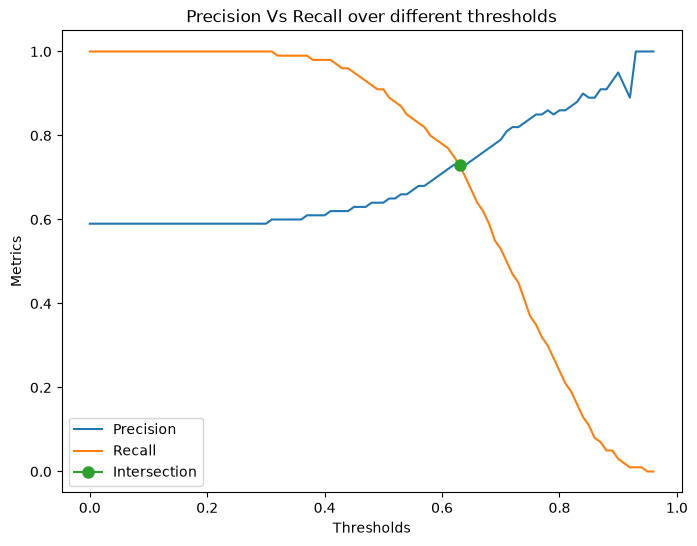

In [22]:
#the point where precision and recall intercepts
fig,ax = plt.subplots(1,1,figsize = (8,6))
ax.plot(select_thres,precisions,label="Precision")
ax.plot(select_thres,recalls,label = "Recall")
ax.plot(thresholds[63],precisions[63],marker = "o",markersize = 8,label = "Intersection")
plt.xlabel("Thresholds")
plt.ylabel("Metrics")
plt.title("Precision Vs Recall over different thresholds")
plt.legend(loc = "lower left")
plt.show();


In [17]:
#Question 5: 5-Fold CV 
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
train_idx,val_idx = next(kfold.split(df_full_train))

In [18]:
fold_train = df_full_train.iloc[train_idx].reset_index(drop=True)
fold_val = df_full_train.iloc[val_idx].reset_index(drop=True)

In [19]:
#encoding categorical features
fold_dv=DictVectorizer(sparse=False)
train_fold = fold_train[categorical_features+numerical_features].to_dict(orient="records")
val_fold = fold_val[categorical_features+numerical_features].to_dict(orient="records")
X_fold_train = fold_dv.fit_transform(train_fold)
X_fold_val = fold_dv.transform(val_fold)

y_fold_train = fold_train.converted.values
y_fold_val = fold_val.converted

In [20]:
auc_list = []
for train_idx,val_idx in kfold.split(df_full_train):
    #separating train and val dataset by each fold
    fold_train = df_full_train.iloc[train_idx].reset_index(drop=True)
    fold_val = df_full_train.iloc[val_idx].reset_index(drop=True)

    #encoding categorical features
    fold_dv=DictVectorizer(sparse=False)
    train_fold = fold_train[categorical_features+numerical_features].to_dict(orient="records")
    val_fold = fold_val[categorical_features+numerical_features].to_dict(orient="records")
    X_fold_train = fold_dv.fit_transform(train_fold)
    X_fold_val = fold_dv.transform(val_fold)

    y_fold_train = fold_train.converted.values
    y_fold_val = fold_val.converted.values

    #building and training model 
    fold_model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    fold_model.fit(X_fold_train,y_fold_train)

    #doing predictions on val dataset
    predictions = fold_model.predict_proba(X_fold_val)[:,1]
    auc_roc = roc_auc_score(y_fold_val.reshape(-1,1),predictions)
    auc_list.append(auc_roc)
    std = np.std(auc_list)
print(round(std,3))
        

0.007


In [21]:

mean_roc = []
std_roc = []
all_in_one = {}
for c in tqdm.tqdm([0.000001, 0.001, 1]):
    auclist = []
    for train_idx,val_idx in tqdm.tqdm(kfold.split(df_full_train)):
        #separating train and val dataset by each fold
        fold_train = df_full_train.iloc[train_idx].reset_index(drop=True)
        fold_val = df_full_train.iloc[val_idx].reset_index(drop=True)

        #encoding categorical features
        fold_dv=DictVectorizer(sparse=False)
        train_fold = fold_train[categorical_features+numerical_features].to_dict(orient="records")
        val_fold = fold_val[categorical_features+numerical_features].to_dict(orient="records")
        X_fold_train = fold_dv.fit_transform(train_fold)
        X_fold_val = fold_dv.transform(val_fold)

        y_fold_train = fold_train.converted.values
        y_fold_val = fold_val.converted.values

        #building and training model 
        fold_model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        fold_model.fit(X_fold_train,y_fold_train)

        #doing predictions on val dataset
        predictions = fold_model.predict_proba(X_fold_val)[:,1]
        auc_roc = roc_auc_score(y_fold_val.reshape(-1,1),predictions)
        auclist.append(auc_roc)
    
    mean_roc.append(round(np.mean(auclist),3))
    std_roc.append(round(np.std(auclist),3))

all_in_one["Parameter C"] = [0.000001, 0.001, 1]
all_in_one["Mean"] = mean_roc
all_in_one["Std"] = std_roc
allin = pd.DataFrame(all_in_one)
allin

5it [00:00, 10.62it/s]00:00<?, ?it/s]
5it [00:00, 11.52it/s]00:00<00:00,  2.10it/s]
5it [00:00, 11.67it/s]00:00<00:00,  2.19it/s]
100%|██████████| 3/3 [00:01<00:00,  2.22it/s]


,Parameter C,Mean,Std
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
